# Inferential statistics on [Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.oneway import anova_oneway

%matplotlib inline
sns.set_theme(style="whitegrid")

In [2]:
csv = "data/student-performance.csv" if os.path.exists("data/student-performance.csv") else "student-performance.csv"
df = pd.read_csv(csv, sep=";")
print(df.shape)
df.head()

(649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
print("missing:", df.isna().sum().sum())
print("duplicates:", df.duplicated().sum())
df[["studytime", "absences", "G1", "G2", "G3"]].describe().round(1)

missing: 0
duplicates: 0


,studytime,absences,G1,G2,G3
count,649.0,649.0,649.0,649.0,649.0
mean,1.9,3.7,11.4,11.6,11.9
std,0.8,4.6,2.7,2.9,3.2
min,1.0,0.0,0.0,0.0,0.0
25%,1.0,0.0,10.0,10.0,10.0
50%,2.0,2.0,11.0,11.0,12.0
75%,2.0,6.0,13.0,13.0,14.0
max,4.0,32.0,19.0,19.0,19.0


Note: G3 is the final grade.

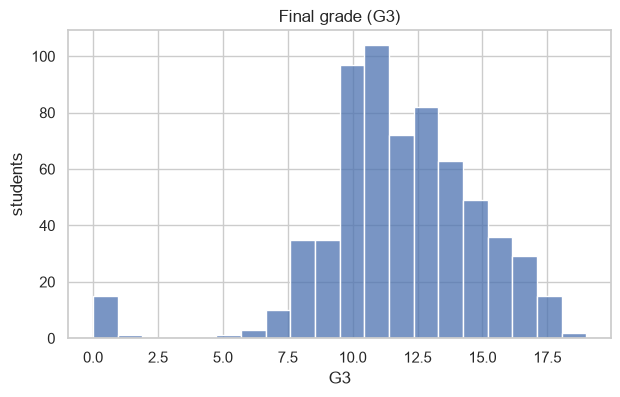

15 students got exactly 0


In [4]:
plt.figure(figsize=(7, 4))
sns.histplot(df.G3, bins=20, color="#4c72b0")
plt.title("Final grade (G3)")
plt.xlabel("G3"); plt.ylabel("students")
plt.show()

print((df.G3 == 0).sum(), "students got exactly 0")

15 students have a final grade of exactly 0. A 0 out of 20 is very rare, so these students are checked before running the tests.

In [5]:
zero = df[df.G3 == 0]
print("absences:", zero.absences.unique())
print("G1 between", zero.G1.min(), "and", zero.G1.max())
print("school:", zero.school.value_counts().to_dict())
print(f"0 absences among the other students: {(df[df.G3 > 0].absences == 0).mean():.0%}")
zero[["school", "sex", "higher", "absences", "G1", "G2", "G3"]]

absences: [0]
G1 between 4 and 11
school: {'MS': 14, 'GP': 1}
0 absences among the other students: 36%


,school,sex,higher,absences,G1,G2,G3
163,GP,M,no,0,11,9,0
440,MS,M,yes,0,7,0,0
519,MS,M,yes,0,8,7,0
563,MS,M,yes,0,7,0,0
567,MS,M,no,0,4,0,0
583,MS,F,no,0,8,6,0
586,MS,F,yes,0,8,8,0
597,MS,F,yes,0,9,0,0
603,MS,F,yes,0,5,0,0
605,MS,F,no,0,5,0,0


All 15 have 0 absences, while only about a third of the other students do. They all got a real grade in G1 (between 4 and 11), and 14 of them are from the MS school. This looks like students who left school or did not take the final exam, so the 0 is probably not a real grade. They are removed from the analysis. Q3 also shows the result with them, to see how much they change it.

In [6]:
df_all = df.copy()
df = df[df.G3 > 0]
print(df.shape)

(634, 33)


### **Q1**. Do students who want higher education get better scores?
**Method**: Comparing two groups using a Welch **t-test**.

A Welch t-test compares the average scores of the two groups: students who want higher education and those who do not. This test is chosen because the groups might have different variances, making it more reliable than a standard t-test when equal variance cannot be assumed. The 95% confidence interval of the gap is also shown.

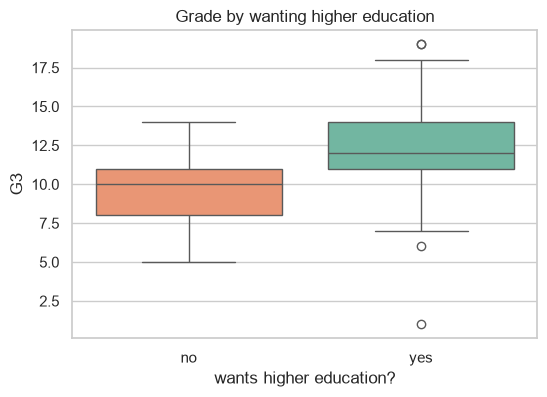

yes: 12.5 (n=570)   no: 9.5 (n=64)
gap: 3.0 points   p = 3.5e-22   d = 1.36
95% CI for the gap: 2.5 to 3.5


In [7]:
yes = df.loc[df.higher == "yes", "G3"]
no  = df.loc[df.higher == "no",  "G3"]

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="higher", y="G3", order=["no", "yes"],
            hue="higher", palette="Set2", legend=False)
plt.title("Grade by wanting higher education")
plt.xlabel("wants higher education?")
plt.show()

res = stats.ttest_ind(yes, no, equal_var=False)
ci = res.confidence_interval()
d = (yes.mean() - no.mean()) / np.sqrt((yes.std(ddof=1)**2 + no.std(ddof=1)**2) / 2)
print(f"yes: {yes.mean():.1f} (n={len(yes)})   no: {no.mean():.1f} (n={len(no)})")
print(f"gap: {yes.mean()-no.mean():.1f} points   p = {res.pvalue:.1e}   d = {d:.2f}")
print(f"95% CI for the gap: {ci.low:.1f} to {ci.high:.1f}")

### **Q2**. Does a mother’s level of education affect her child's grades?
**Method**: Four groups were compared using **Welch's ANOVA**. A Levene test was done first to check variances, and a Games-Howell test followed.

Only 6 students have a mother with no education (Medu = 0). That is too few for a group, so they are put together with group 1. Levene's test shows the variances are not equal after removing the G3 = 0 students, so Welch's ANOVA is used. It works like the Welch t-test in Q1. Games-Howell is a post hoc test that also does not assume equal variances, and it shows which groups differ.

{1: 144, 2: 181, 3: 138, 4: 171}
Levene p = 0.03


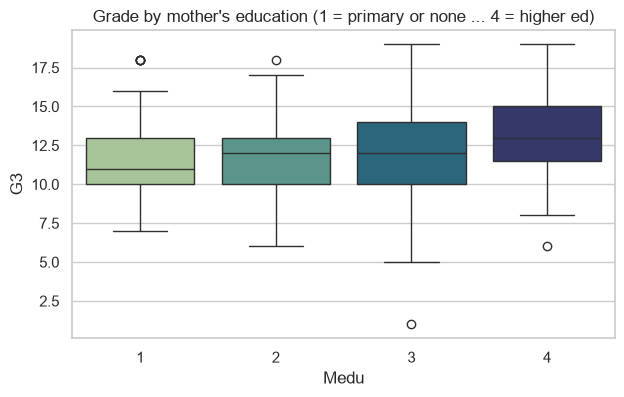

Welch ANOVA p = 3.0e-12   eta^2 = 0.09


In [8]:
df["Medu"] = df.Medu.replace(0, 1)
levels = sorted(df.Medu.unique())
groups = [df.loc[df.Medu == k, "G3"].values for k in levels]
print(df.Medu.value_counts().sort_index().to_dict())
print(f"Levene p = {stats.levene(*groups).pvalue:.2f}")

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Medu", y="G3", hue="Medu", palette="crest", legend=False)
plt.title("Grade by mother's education (1 = primary or none ... 4 = higher ed)")
plt.xlabel("Medu")
plt.show()

welch = anova_oneway(groups, use_var="unequal")
grand = df.G3.mean()
eta2 = sum(len(g)*(g.mean()-grand)**2 for g in groups) / ((df.G3-grand)**2).sum()
print(f"Welch ANOVA p = {welch.pvalue:.1e}   eta^2 = {eta2:.2f}")

In [9]:
gh = stats.tukey_hsd(*groups, equal_var=False)
print("Games-Howell p-values")
pd.DataFrame(gh.pvalue, index=levels, columns=levels).round(3)

Games-Howell p-values


,1,2,3,4
1,1.000,0.022,0.066,0.0
2,0.022,1.000,1.000,0.0
3,0.066,1.000,1.000,0.0
4,0.000,0.000,0.000,1.0


Medu is ordered (a higher number means more education), so a Spearman correlation also checks if grades go up step by step.

In [10]:
rho, p_rho = stats.spearmanr(df.Medu, df.G3)
print(f"Spearman rho = {rho:.2f}   p = {p_rho:.1e}")

Spearman rho = 0.29   p = 1.0e-13


### **Q3**. Do absences affect grades?
**Method**: Measure the **correlation** between the two numbers and add a trend line.

The relationship between absences and grades is checked using correlation, and a simple line is used to show the trend.

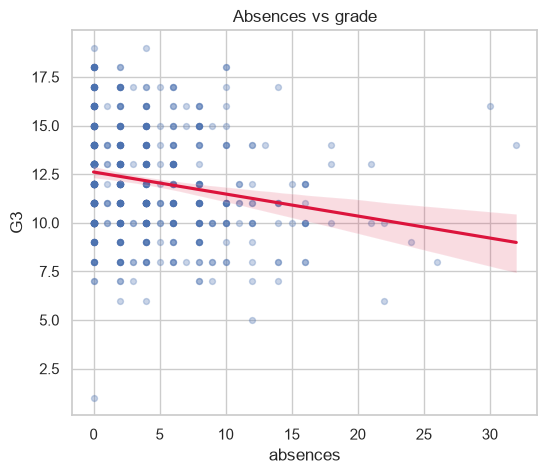

r = -0.20   p = 6.5e-07   r^2 = 0.038


In [11]:
plt.figure(figsize=(6, 5))
sns.regplot(data=df, x="absences", y="G3",
            scatter_kws={"alpha": 0.3, "s": 18}, line_kws={"color": "crimson"})
plt.title("Absences vs grade")
plt.show()

r, p = stats.pearsonr(df.absences, df.G3)
print(f"r = {r:.2f}   p = {p:.1e}   r^2 = {r**2:.3f}")

Absences are very skewed: most students have only a few, but some have up to 32. Spearman's rank correlation works with ranks, so a few large values have less effect.

In [12]:
rho, p_s = stats.spearmanr(df.absences, df.G3)
print(f"Spearman rho = {rho:.2f}   p = {p_s:.1e}")

Spearman rho = -0.21   p = 5.2e-08


If the 15 removed students are kept, the correlation is much weaker. They all have 0 absences and a grade of 0, so they sit in one corner of the plot and pull the line toward zero.

In [13]:
r_all, p_all = stats.pearsonr(df_all.absences, df_all.G3)
print(f"with G3 = 0 students: r = {r_all:.2f}   p = {p_all:.3f}")

with G3 = 0 students: r = -0.09   p = 0.020


### **Q4**. Is there a difference between boys and girls in wanting higher education?
**Method**: The data has two categories, so a **chi-square** test is used.

A chi-square test compares boys and girls to see if there is a difference in their choices about pursuing higher education.

higher  no  yes
sex            
F       32  344
M       32  226 

smallest expected count: 26
want higher ed —  F: 91%   M: 88%
chi2 = 2.14   p = 0.14   Cramer's V = 0.06


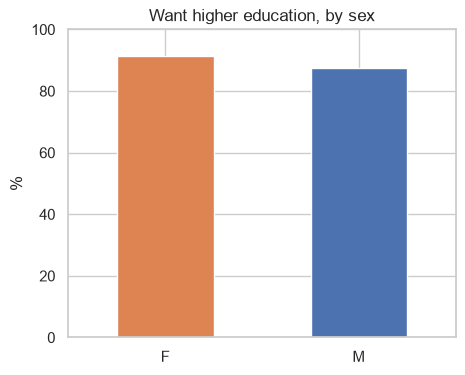

In [14]:
table = pd.crosstab(df.sex, df.higher)
chi2, p, dof, expected = stats.chi2_contingency(table)
V = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
share = table["yes"] / table.sum(axis=1) * 100

print(table, "\n")
print("smallest expected count:", round(expected.min()))
print(f"want higher ed —  F: {share['F']:.0f}%   M: {share['M']:.0f}%")
print(f"chi2 = {chi2:.2f}   p = {p:.2f}   Cramer's V = {V:.2f}")

plt.figure(figsize=(5, 4))
share.plot(kind="bar", color=["#dd8452", "#4c72b0"])
plt.title("Want higher education, by sex")
plt.ylabel("%"); plt.xlabel(""); plt.xticks(rotation=0); plt.ylim(0, 100)
plt.show()

## Questions and Answers

Q1. Do students who want higher education get better scores?

* Yes. They score about 3 points higher on average (95% CI: 2.5 to 3.5). The difference is significant. (t-test, d ≈ 1.36)

Q2. Does a mother’s level of education affect her child's grades?

* Yes, but only a little. It explains around 9% of the difference in grades. Grades go up slowly with the mother's education, and the biggest jump is in the highest education group. (Welch's ANOVA, η² ≈ 0.09, Spearman ≈ 0.29)

Q3. Do absences affect grades?

* Yes, but the effect is small. More absences usually mean slightly lower grades, but the relationship is weak. Keeping the 15 students with a grade of 0 makes it look even weaker (r ≈ −0.09). (Pearson ≈ −0.20, Spearman ≈ −0.21)

Q4. Is there a difference between boys and girls in wanting higher education?

* No real difference. Both groups are very similar (91% vs 88%). (chi-square test)

## Key Consideration

A small p-value means there is a real link, but it does not show how big the effect is. For example, both Q1 and Q3 are “significant,” but one effect is large and the other is small. These results do not show cause and effect, since the data were only observed. The study looked at 634 students from just two schools, so the findings might not apply to other groups.